In [1]:
import os
import torch
from IPython.display import Image, clear_output
print('PyTorch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

PyTorch 2.3.1+cu121 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', major=8, minor=0, total_memory=40513MB, multi_processor_count=108)


In [2]:
!git clone https://github.com/AmeyAvhad/YOLOV3.git yolov3

Cloning into 'yolov3'...
remote: Enumerating objects: 76, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 76 (delta 25), reused 68 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (76/76), 1.39 MiB | 8.13 MiB/s, done.
Resolving deltas: 100% (25/25), done.


In [3]:
# REPLACE THIS LINK WITH YOUR OWN
!curl -L "https://app.roboflow.com/ds/ZGzh105gkd?key=rmQQrMSZuh" | jar -x


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   904  100   904    0     0   3745      0 --:--:-- --:--:-- --:--:--  3751
 99  185M   99  184M    0     0   149M      0  0:00:01  0:00:01 --:--:--  234M
curl: (23) Failure writing output to destination


## Organize data and labels for Ultralytics YOLOv3 Implementation

Ultalytics's implemention of YOLOv3 calls for [a specific file management](https://github.com/ultralytics/yolov3/wiki/Train-Custom-Data) where our images are in a folder called `images` and corresponding labels in a folder called `labels`. The image and label names must match identically. Fortunately, our files are named appropriately from Roboflow.

We need to reorganize the folder structure slightly.

In [4]:
%cd train

/content/train


In [5]:
%ls

08888710-2-_jpg.rf.716777936981f994a37b80e92be8e48a.jpg
08888710-2-_jpg.rf.716777936981f994a37b80e92be8e48a.txt
08888710-2-_jpg.rf.939248a3952a919e72d5888cfb891f31.jpg
08888710-2-_jpg.rf.939248a3952a919e72d5888cfb891f31.txt
09132978_20141226_WL_jpg.rf.cfb3d1a3baa81e698992af52dd81f6ae.jpg
09132978_20141226_WL_jpg.rf.cfb3d1a3baa81e698992af52dd81f6ae.txt
11218613-2-_jpg.rf.38265d036f17736b240a5b0afb79d3ab.jpg
11218613-2-_jpg.rf.38265d036f17736b240a5b0afb79d3ab.txt
14608492-2-_jpg.rf.6b3717fc0dae10b9b6652c187e29e539.jpg
14608492-2-_jpg.rf.6b3717fc0dae10b9b6652c187e29e539.txt
14608492-2-_jpg.rf.d6e52f6fad63f4455e8f911381826789.jpg
14608492-2-_jpg.rf.d6e52f6fad63f4455e8f911381826789.txt
17491749_20190422_ES_0_10_10_jpg.rf.2db1ba10f27aea4f5f19bd1bfe656950.jpg
17491749_20190422_ES_0_10_10_jpg.rf.2db1ba10f27aea4f5f19bd1bfe656950.txt
17491749_20190422_ES_0_10_10_jpg.rf.a3fa1b31a5bf8422aed86e869467c909.jpg
17491749_20190422_ES_0_10_10_jpg.rf.a3fa1b31a5bf8422aed86e869467c909.txt
17491749_20190422_

In [6]:
%mkdir labels
%mkdir images

In [7]:
%mv *.jpg ./images/
%mv *.txt ./labels/

In [8]:
%cd images

/content/train/images


In [9]:
# create Ultralytics specific text file of training images
file = open("train_images_roboflow.txt", "w")
for root, dirs, files in os.walk("."):
    for filename in files:
      # print("../train/images/" + filename)
      if filename == "train_images_roboflow.txt":
        pass
      else:
        file.write("../train/images/" + filename + "\n")
file.close()

In [10]:
%cat train_images_roboflow.txt

../train/images/Img20200930-154752528_jpg.rf.4e6e8fa7c29ede1014f27e061d934139.jpg
../train/images/REC20201222-150909177__000374_jpg.rf.42abd5510e0ba936a0f6a6e7310e3193.jpg
../train/images/REC20201216-121910254__007362_jpg.rf.321d63b29a028f4373155f5739748b14.jpg
../train/images/REC20201211-084510723__000073_jpg.rf.d43b4c2390d7d8f5a7ebbda3d9d3fc12.jpg
../train/images/IPCL-V2-JESB2-IPCLIV-JESB1_000244_jpg.rf.8ac9d1a4d32caac86f9cd294d606569c.jpg
../train/images/REC20200904-133725241__001331_jpg.rf.59293fa1ce9c38307aeacc928125329f.jpg
../train/images/REC20200930-152531313__001401_jpg.rf.7937b71cbd8a9a4c7c7cee27af177b2c.jpg
../train/images/REC20200818-100424995__000576_jpg.rf.826e81a53e242daa6465c6724e3f8479.jpg
../train/images/21591967_20180927_ES_0_31_31_jpg.rf.061dc0848554f374e8e252a9986d26e3.jpg
../train/images/Img20200805-112522383_jpg.rf.9fd3280bebabc92c99b54874cc54a217.jpg
../train/images/REC20200929-093407061__004415_jpg.rf.936b0acb54f57693f5b2bc5c95fbf2b3.jpg
../train/images/REC2020

In [11]:
%cd ../../valid

/content/valid


In [12]:
%mkdir labels
%mkdir images

In [13]:
%mv *.jpg ./images/
%mv *.txt ./labels/

In [14]:
%cd images

/content/valid/images


In [15]:
# create Ultralytics specific text file of validation images
file = open("valid_images_roboflow.txt", "w")
for root, dirs, files in os.walk("."):
    for filename in files:
      # print("../train/images/" + filename)
      if filename == "valid_images_roboflow.txt":
        pass
      else:
        file.write("../valid/images/" + filename + "\n")
file.close()

In [16]:
%cat valid_images_roboflow.txt

../valid/images/REC20201016-134258176__000042_jpg.rf.ab34cae1a40bdedac6f3018a1b000385.jpg
../valid/images/REC20200917-102257151__000078_jpg.rf.4533f494f68ab2ad7ca14ac206f426ad.jpg
../valid/images/REC20200804-100617134__001178_jpg.rf.df3898af023ef36c5be03b4cc9fa4fef.jpg
../valid/images/REC20201215-172408125__000237_jpg.rf.3c832441453d2f36baf6949f99cf2b00.jpg
../valid/images/REC20200819-110057354__000387_jpg.rf.9368e674c6f3737f920cfcc669fb8d65.jpg
../valid/images/REC20200805-113516181__000053_jpg.rf.f1ebf40ad06766dc4c8916301df312f4.jpg
../valid/images/S90-2-_jpg.rf.8957665675fe2e9c8ea28479dc925b72.jpg
../valid/images/REC20200916-144316853__000210_jpg.rf.4922437213f6f64a80e2f4ad6394a5c4.jpg
../valid/images/REC20201117-154137917__003164_jpg.rf.243beb53e512aaf84d26b7487993eb27.jpg
../valid/images/REC20201118-145940603__000577_jpg.rf.42bc679cecc70fbad60bd65ccd38afa9.jpg
../valid/images/REC20200930-154717808__000443_jpg.rf.85d77689d883f33e8e2f8b6b629a75a3.jpg
../valid/images/S02-4-_jpg.rf.17f

## Set up model config

We should configure our model for training.

This requires editing the `roboflow.data` file, which tells our model where to find our data, our numbers of classes, and our class label names.

Our paths for our labels and images are correct.

But we need to update our class names. That's handled below..




In [17]:
%cd ../../yolov3/data

/content/yolov3/data


In [18]:
# display class labels imported from Roboflow
%cat ../../train/_darknet.labels

0
1
10
2
3
4
5
6
7
8
9

In [19]:
# convert .labels to .names for Ultralytics specification
%cat ../../train/_darknet.labels > ../../train/roboflow_data.names

In [20]:
def get_num_classes(labels_file_path):
    classes = 0
    with open(labels_file_path, 'r') as f:
      for line in f:
        classes += 1
    return classes

In [21]:
# update the roboflow.data file with correct number of classes
import re

num_classes = get_num_classes("../../train/_darknet.labels")
with open("roboflow.data") as f:
    s = f.read()
with open("roboflow.data", 'w') as f:

    # Set number of classes num_classes.
    s = re.sub('classes=[0-9]+',
               'classes={}'.format(num_classes), s)
    f.write(s)

In [22]:
# display updated number of classes
%cat roboflow.data

classes=11
train=../train/images/train_images_roboflow.txt
valid=../valid/images/valid_images_roboflow.txt
names=../train/roboflow_data.names


## Training our model

Once we have our data prepped, we'll train our model using the train script.

By default, this script trains for 300 epochs.

In [23]:
%cd ../

/content/yolov3


In [24]:
import os
import gdown

# Create the weights directory if it doesn't exist
if not os.path.exists('weights'):
    os.makedirs('weights')

# Google Drive file ID
file_id = '1MLsnr9R-eeWAQf6_ylA33pPIOpVrARLp'

# Destination path
destination = 'weights/'

# Construct the download URL
download_url = f'https://drive.google.com/uc?id={file_id}'

# Download the file
gdown.download(download_url, destination, quiet=False)


Downloading...
From (original): https://drive.google.com/uc?id=1MLsnr9R-eeWAQf6_ylA33pPIOpVrARLp
From (redirected): https://drive.google.com/uc?id=1MLsnr9R-eeWAQf6_ylA33pPIOpVrARLp&confirm=t&uuid=46e0451e-70b2-413f-95de-751f5f001525
To: /content/yolov3/weights/yolov3-spp-ultralytics.pt
100%|██████████| 252M/252M [00:02<00:00, 103MB/s]


'weights/yolov3-spp-ultralytics.pt'

In [25]:
import os
import gdown

# Create the weights directory if it doesn't exist
if not os.path.exists('weights'):
    os.makedirs('weights')

# Google Drive file ID
file_id = '1AlYTbBauDMRJqkFpyQaarFx7ILDDPAde'

# Destination path
destination = 'weights/'

# Construct the download URL
download_url = f'https://drive.google.com/uc?id={file_id}'

# Download the file
gdown.download(download_url, destination, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1AlYTbBauDMRJqkFpyQaarFx7ILDDPAde
From (redirected): https://drive.google.com/uc?id=1AlYTbBauDMRJqkFpyQaarFx7ILDDPAde&confirm=t&uuid=78db78fe-a844-4ada-ab34-4890dc5ac1cb
To: /content/yolov3/weights/yolov3.pt
100%|██████████| 124M/124M [00:01<00:00, 118MB/s]


'weights/yolov3.pt'

In [26]:
import os
import gdown

# Create the weights directory if it doesn't exist
if not os.path.exists('weights'):
    os.makedirs('weights')

# Google Drive file ID
file_id = '1oSbak8E9PAD0-t02uzjnkoe3qAlX1hmO'

# Destination path
destination = 'weights/'

# Construct the download URL
download_url = f'https://drive.google.com/uc?id={file_id}'

# Download the file
gdown.download(download_url, destination, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1oSbak8E9PAD0-t02uzjnkoe3qAlX1hmO
From (redirected): https://drive.google.com/uc?id=1oSbak8E9PAD0-t02uzjnkoe3qAlX1hmO&confirm=t&uuid=24b6d86a-1b1e-4cf0-8716-b155c0caaaea
To: /content/yolov3/weights/yolov3-spp.pt
100%|██████████| 126M/126M [00:00<00:00, 147MB/s]


'weights/yolov3-spp.pt'

In [27]:
!bash /content/yolov3/weights/download_yolov3_weights.sh

In [28]:
!ls

cfg   detect.py   evaluate.py	  LICENSE    __pycache__  requirements.txt  train.py	    utils
data  Dockerfile  examples.ipynb  models.py  README.md	  test.py	    Tutorial.ipynb  weights


In [29]:
!python3 train.py --data data/roboflow.data --epochs 600

Namespace(epochs=600, batch_size=16, accumulate=4, cfg='cfg/yolov3-spp.cfg', data='data/roboflow.data', multi_scale=False, img_size=[416], rect=False, resume=False, nosave=False, notest=False, evolve=False, bucket='', cache_images=False, weights='weights/yolov3-spp-ultralytics.pt', name='', device='', adam=False, single_cls=False, var=None)
Using CUDA device0 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', total_memory=40513MB)

2024-08-24 12:03:17.706382: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-08-24 12:03:17.724265: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-24 12:03:17.745391: E external/local_xla/xla/stream

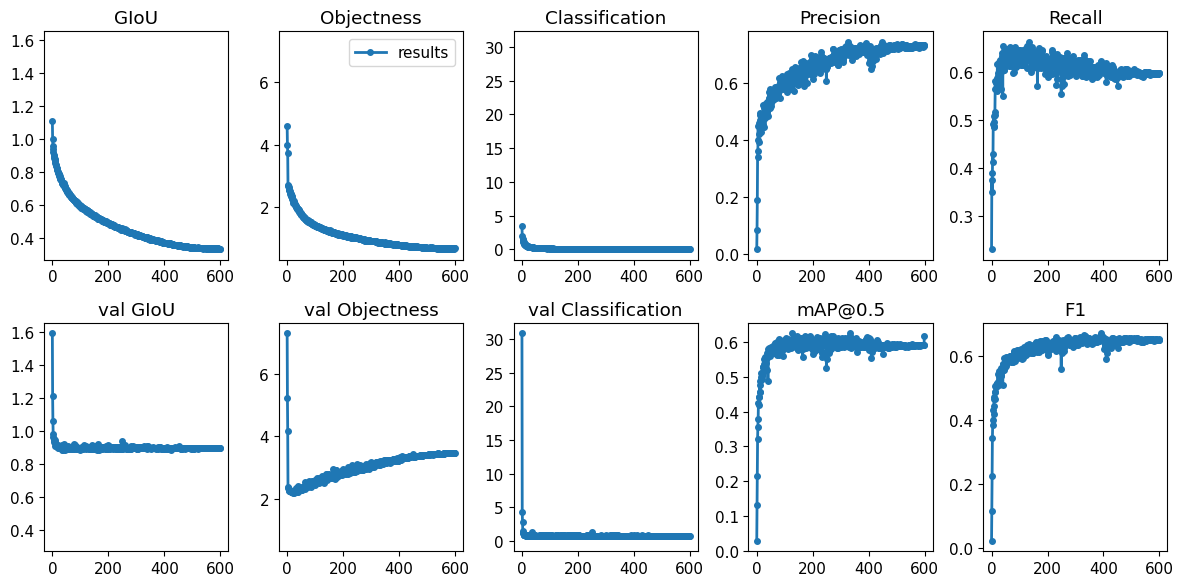

In [30]:
from utils import utils; utils.plot_results()

In [31]:
!python3 evaluate.py --data data/roboflow.data --weights weights/best.pt --iou 0.6

Namespace(cfg='cfg/yolov3-spp.cfg', data='data/roboflow.data', weights='weights/best.pt', batch_size=32, img_size=416, conf_thres=0.001, iou_thres=0.6, save_json=False, task='test', device='', single_cls=False)
Using CUDA device0 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', total_memory=40513MB)

Model Summary: 225 layers, 6.29987e+07 parameters, 6.29987e+07 gradients
Fusing layers...
Model Summary: 152 layers, 6.29719e+07 parameters, 6.29719e+07 gradients
Caching labels (825 found, 0 missing, 0 empty, 0 duplicate, for 825 images): 100% 825/825 [00:00<00:00, 6301.71it/s]
               Class    Images   Targets         P         R   mAP@0.5        F1:   0% 0/26 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/functional.py:512: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3587.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defi

## Conduct inference and display results



### Conduct inference

The below script has a few key arguments we're using:
- **Weights**: we're specifying the weights to use for our model should be those that we most recently used in training
- **Source**: we're specifying the source images we want to use for our predictions
- **Names**: we're defining the names we want to use. Here, we're referencing `roboflow_data.names`, which we created from our Roboflow `_darknet.labels`italicized text above.

In [32]:
!ls ../test

11218613-2-_jpg.rf.d30f155bfb8b9a6768e0093c823a7b3c.jpg
11218613-2-_jpg.rf.d30f155bfb8b9a6768e0093c823a7b3c.txt
17491749_20190422_ES_0_7_7_jpg.rf.21ed1e97d47092b451e1e70b233309dc.jpg
17491749_20190422_ES_0_7_7_jpg.rf.21ed1e97d47092b451e1e70b233309dc.txt
180518-0938-52_jpg.rf.05ede30164d7fd43bd9d8537d35fdb77.jpg
180518-0938-52_jpg.rf.05ede30164d7fd43bd9d8537d35fdb77.txt
190313-1103-40_jpg.rf.b1e6bf8f9d58c259538f4b62880cbe48.jpg
190313-1103-40_jpg.rf.b1e6bf8f9d58c259538f4b62880cbe48.txt
21591967_20180927_ES_0_21_21_jpg.rf.4958988b73ce1536439f68da96249328.jpg
21591967_20180927_ES_0_21_21_jpg.rf.4958988b73ce1536439f68da96249328.txt
22141522_20150320_SCC-WL_jpg.rf.7c4f233963e2754ba67935f873bf1848.jpg
22141522_20150320_SCC-WL_jpg.rf.7c4f233963e2754ba67935f873bf1848.txt
22141522_20150320_SCC-WL_jpg.rf.86beed0c1d2d1049ee7a105a4f784bd2.jpg
22141522_20150320_SCC-WL_jpg.rf.86beed0c1d2d1049ee7a105a4f784bd2.txt
22948922_20141016_WL-SCC_jpg.rf.61da07f2b66932a53b913c4d2a5d7b16.jpg
22948922_20141016_W

In [33]:
!python3 detect.py --weights weights/best.pt --source=../test --names=../train/roboflow_data.names

Namespace(cfg='cfg/yolov3-spp.cfg', names='../train/roboflow_data.names', weights='weights/best.pt', source='../test', output='output', img_size=416, conf_thres=0.3, iou_thres=0.6, fourcc='mp4v', half=False, device='', view_img=False, save_txt=False, classes=None, agnostic_nms=False)
Using CUDA device0 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', total_memory=40513MB)

Model Summary: 225 layers, 6.29987e+07 parameters, 6.29987e+07 gradients
/usr/local/lib/python3.10/dist-packages/torch/functional.py:512: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3587.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
image 1/412 ../test/11218613-2-_jpg.rf.d30f155bfb8b9a6768e0093c823a7b3c.jpg: 416x416 1 5s, Done. (0.324s)
image 2/412 ../test/17491749_20190422_ES_0_7_7_jpg.rf.21ed1e97d47092b451e1e70b233309dc.jpg: 416x416 1 0s, 1 1s, 1 10s, 1 2s, 1 3s,

### Displaying our results

Ultralytics generates predictions which include the labels and bounding boxes "printed" directly on top of our images. They're saved in our `output` directory within the YOLOv3 repo we cloned above.

In [ ]:
# import libraries for display
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Image
from glob import glob
import random
import PIL

REC20200804-103743676__000481_jpg.rf.8a4316a779596bce4798cd73283f0356.jpg


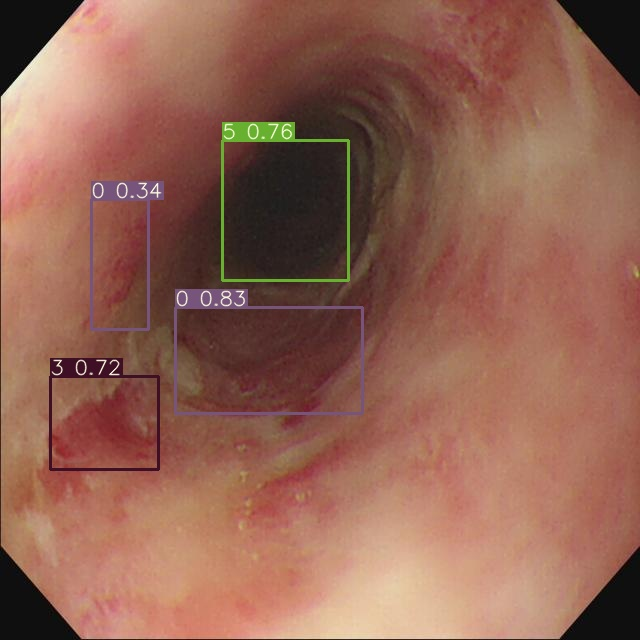

In [ ]:
# plot just one random image prediction
filename = random.choice(os.listdir('./output'))
print(filename)
Image('./output/' + filename)

In [ ]:
# grab all images from our output directory
images = [ PIL.Image.open(f) for f in glob('./output/*') ]

In [ ]:
# convert images to numPy
def img2array(im):
    if im.mode != 'RGB':
        im = im.convert(mode='RGB')
    return np.fromstring(im.tobytes(), dtype='uint8').reshape((im.size[1], im.size[0], 3))

In [ ]:
# create array of numPy images
np_images = [ img2array(im) for im in images ]

<ipython-input-37-de515a6c7ad3>:5: DeprecationWarning: The binary mode of fromstring is deprecated, as it behaves surprisingly on unicode inputs. Use frombuffer instead
  return np.fromstring(im.tobytes(), dtype='uint8').reshape((im.size[1], im.size[0], 3))


In [ ]:
# plot ALL results in test directory (NOTE: adjust figsize as you please)
for img in np_images:
    plt.figure(figsize=(8, 6))
    plt.imshow(img)

## Save Our Weights

We can save the weights of our model to use them for inference in the future, or pick up training where we left off.

We can first save them locally. We'll connect our Google Drive, and save them there.


In [35]:
import shutil
from google.colab import files

# Define the directory and output zip file name
directory_to_zip = '/content/yolov3/output'
output_filename = '/content/yolov3_runs.zip'

# Zip the directory
shutil.make_archive(output_filename.replace('.zip', ''), 'zip', directory_to_zip)

# Download the zipped file
files.download(output_filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>